In [1]:
import numpy as np
import numpy as np
from scipy import special
from scipy.special import erfc, erfi
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from scipy.special import erfc, erfcx, erf
from cdm_ewald.CDM_Ewald_direct import CDM_Ewald_direct

In [2]:
# parameters
# import silver dielectric constant
optical_data = pd.read_csv(
    "silver_optical_data.csv"
)
# Original data

wavelength_orig = optical_data["lambda"].to_numpy()

epsP_orig = optical_data["e1"].to_numpy() + 1j * optical_data["e2"].to_numpy()

# Add new wavelengths

add_wavelength_list = np.arange(470/50, 490/50, 0.1)  # 470, 475, 480, 485

# Merge and sort uniquely

wavelength_list = np.unique(

    np.concatenate((wavelength_orig, add_wavelength_list))

)

# Interpolate the real and imaginary parts separately

epsP = (

    np.interp(wavelength_list, wavelength_orig, epsP_orig.real)

    + 1j * np.interp(wavelength_list, wavelength_orig, epsP_orig.imag)

)

# Other quantities

k_list = 2 * np.pi / wavelength_list

k_direction = np.array([0, 0, 1])
def phi_1(x):
    return np.sin(x)/x - np.cos(x)
def xi_1(x):
    return np.sin(x)/x - np.cos(x) + 1j*(-np.cos(x) - np.sin(x)/x)
def phi_1_prime(x):
    return -np.sin(x)/x**2 + np.cos(x)/x + np.sin(x)
def xi_1_prime(x):
    return -np.sin(x)/x**2 + np.cos(x)/x + np.sin(x) + 1j*(np.cos(x)/x**2 + np.sin(x)/x - np.cos(x))
x_array = k_list
m_array = np.sqrt(epsP)
a1_array_up = m_array*phi_1(m_array*x_array)*phi_1_prime(x_array)-phi_1(x_array)*phi_1_prime(m_array*x_array)
a1_array_down = m_array*phi_1(m_array*x_array)*xi_1_prime(x_array)-xi_1(x_array)*phi_1_prime(m_array*x_array)
a1_array = a1_array_up/a1_array_down
polarizability_list = 1j*1.5*a1_array/(x_array**3) * 4 * np.pi
wavelength_nm = wavelength_list * 50
wavevector_direction = np.array([0,0,1])
polarization_direction = np.array([1,0,0])


In [48]:
import numpy as np

a = 200.0
layer_separation_array = np.arange(100,110,10)
# ============================================================
# Minimal common cell in the NEW coordinate convention
# ============================================================

a_cell = np.sqrt(5) * a

C1 = np.array([a_cell, 0.0])
C2 = np.array([0.0, a_cell])

C = np.vstack([C1, C2])
dips_list = []

# ============================================================
# Primitive vectors in the NEW coordinate convention
# Stored as columns
# ============================================================
# Bottom lattice
for layer_separation in layer_separation_array:
    A = (a / np.sqrt(5)) * np.array([
        [ 1.0,  2.0],
        [-2.0,  1.0],
    ])

    # Top lattice
    B = (a / np.sqrt(5)) * np.array([
        [ 2.0,  1.0],
        [-1.0,  2.0],
    ])


    # ============================================================
    # Same original algorithm
    # ============================================================

    def points_inside_supercell(
        primitive_vectors,
        supercell_vectors,
        search_limit=20,
        tolerance=1e-9,
    ):

        inverse_supercell = np.linalg.inv(supercell_vectors)

        positions = []
        lattice_indices = []
        fractional_coordinates = []

        for i in range(-search_limit, search_limit + 1):
            for j in range(-search_limit, search_limit + 1):

                position = primitive_vectors @ np.array(
                    [i, j],
                    dtype=float,
                )

                fractional = inverse_supercell @ position

                inside = (
                    np.all(fractional >= -tolerance)
                    and np.all(fractional < 1.0 - tolerance)
                )

                if inside:
                    positions.append(position)
                    lattice_indices.append([i, j])
                    fractional_coordinates.append(fractional)

        positions = np.asarray(positions)
        lattice_indices = np.asarray(lattice_indices, dtype=int)
        fractional_coordinates = np.asarray(fractional_coordinates)

        order = np.lexsort((
            fractional_coordinates[:, 1],
            fractional_coordinates[:, 0],
        ))

        return (
            positions[order],
            lattice_indices[order],
            fractional_coordinates[order],
        )


    # ============================================================
    # Generate bottom and top positions
    # ============================================================

    bottom_xy, bottom_ij, bottom_uv = points_inside_supercell(
        A, C
    )

    top_xy, top_ij, top_uv = points_inside_supercell(
        B, C
    )

    print("C:")
    print(C)

    print("\nBottom:")
    print(bottom_xy)

    print("\nTop:")
    print(top_xy)

    print("\nNumber per layer:")
    print(len(bottom_xy), len(top_xy))
    bottom_xy, bottom_ij, bottom_uv = points_inside_supercell(A, C)
    top_xy, top_ij, top_uv = points_inside_supercell(B, C)

    bottom_xyz = np.column_stack([
        bottom_xy,
        np.zeros(len(bottom_xy))
    ])

    top_xyz = np.column_stack([
        top_xy,
        np.full(len(top_xy), layer_separation)
    ])
    positions = np.vstack([
    bottom_xyz,
    top_xyz,
    ])
    cdm = CDM_Ewald_direct(C/50,positions/50,polarizability_list,k_list, wavevector_direction,polarization_direction)
    cdm.compute()
    dips_list.append(cdm.dips)

C:
[[447.2135955   0.       ]
 [  0.        447.2135955]]

Bottom:
[[  0.          0.       ]
 [ 89.4427191 268.3281573]
 [178.8854382  89.4427191]
 [268.3281573 357.7708764]
 [357.7708764 178.8854382]]

Top:
[[  0.          0.       ]
 [ 89.4427191 178.8854382]
 [178.8854382 357.7708764]
 [268.3281573  89.4427191]
 [357.7708764 268.3281573]]

Number per layer:
5 5
[[0.         0.         1.04719755]
 [0.         0.         1.0332813 ]
 [0.         0.         1.01973007]
 [0.         0.         1.00652969]
 [0.         0.         0.99366669]
 [0.         0.         0.98112831]
 [0.         0.         0.96890241]
 [0.         0.         0.95697745]
 [0.         0.         0.94534247]
 [0.         0.         0.93398701]
 [0.         0.         0.92290111]
 [0.         0.         0.91207529]
 [0.         0.         0.9015005 ]
 [0.         0.         0.89116812]
 [0.         0.         0.88106989]
 [0.         0.         0.87119796]
 [0.         0.         0.8615448 ]
 [0.         0.     

/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/incident_field_builder.py:64: RuntimeWarning: divide by zero encountered in matmul
  phase = np.exp(1j * wave_vectors @ positions.T)
/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/incident_field_builder.py:64: RuntimeWarning: overflow encountered in matmul
  phase = np.exp(1j * wave_vectors @ positions.T)
/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/incident_field_builder.py:64: RuntimeWarning: invalid value encountered in matmul
  phase = np.exp(1j * wave_vectors @ positions.T)


run for 2
run for 3
run for 4
run for 5
run for 6
run for 7
run for 8
run for 9
run for 10
run for 11
run for 12
run for 13
run for 14
run for 15
run for 16
run for 17
run for 18
run for 19
run for 20
run for 21
run for 22
run for 23
run for 24
run for 25
run for 26
run for 27
run for 28
run for 29
run for 30
run for 31
run for 32
run for 33
run for 34
run for 35
run for 36
run for 37
run for 38
run for 39
run for 40
run for 41
run for 42
run for 43
run for 44
run for 45
run for 46
run for 47
run for 48
run for 49
run for 50
run for 51
run for 52
run for 53
run for 54
run for 55
run for 56
run for 57
run for 58
run for 59
run for 60
run for 61
run for 62
run for 63
run for 64
run for 65
run for 66
run for 67
run for 68
run for 69
run for 70
run for 71
run for 72
run for 73
run for 74
run for 75
run for 76
run for 77
run for 78
run for 79
run for 80
run for 81
run for 82
run for 83
run for 84
run for 85
run for 86
run for 87
run for 88
run for 89
run for 90
run for 91
run for 92
run for

(5, 2)
(5, 2)


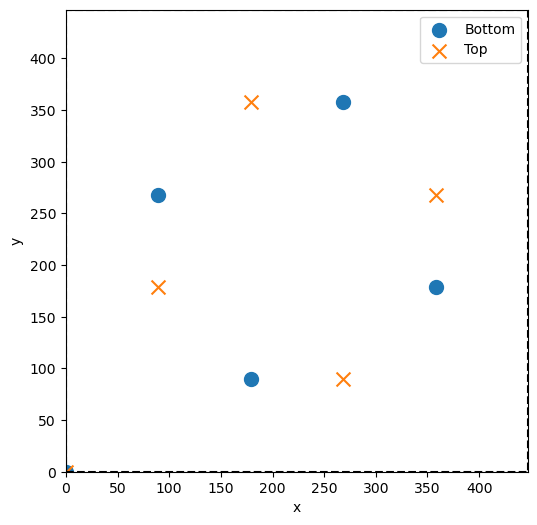

In [34]:
a = 200.0
layer_separation_array = np.arange(100,400,10)
# ============================================================
# Minimal common cell in the NEW coordinate convention
# ============================================================

a_cell = np.sqrt(5) * a

C1 = np.array([a_cell, 0.0])
C2 = np.array([0.0, a_cell])

C = np.vstack([C1, C2])
bottom_xy, _, _ = points_inside_supercell(A, C)
top_xy, _, _ = points_inside_supercell(B, C)

print(bottom_xy.shape)  # (5, 2)
print(top_xy.shape)     # (5, 2)

plt.figure(figsize=(6, 6))

plt.scatter(bottom_xy[:, 0], bottom_xy[:, 1],
            s=100, marker='o', label='Bottom')

plt.scatter(top_xy[:, 0], top_xy[:, 1],
            s=100, marker='x', label='Top')

# boundary of the NEW C unit cell
boundary = np.array([
    [0, 0],
    C1,
    C1 + C2,
    C2,
    [0, 0]
])

plt.plot(boundary[:, 0], boundary[:, 1], 'k--')

plt.xlim(0, np.sqrt(5)*a)
plt.ylim(0, np.sqrt(5)*a)
plt.gca().set_aspect('equal')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [25]:
bottom_xy.shape

(5, 2)

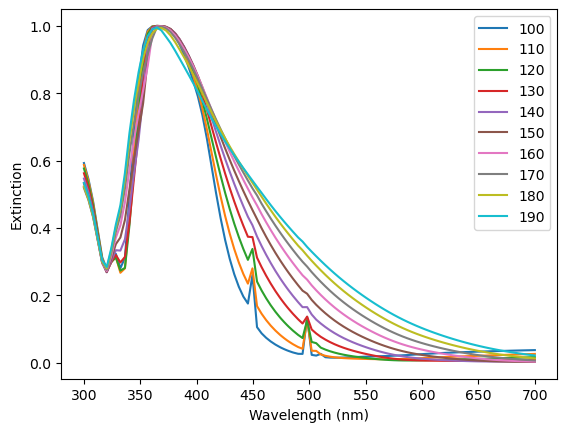

In [50]:
import numpy as np

a = 200.0
layer_separation_array = np.arange(100,400,10)
C1 = np.array([a, 0.0])
C2 = np.array([0.0, a])

C = np.vstack([C1, C2])
dips_simple_list = []
for layer_separation in layer_separation_array:
    







    positions = np.array([[0,0,0],[0,0,layer_separation]])
    cdm = CDM_Ewald_direct(C/50,positions/50,polarizability_list,k_list, wavevector_direction,polarization_direction)
    cdm.compute()
    dips_simple_list.append(cdm.dips)
    

[[0.         0.         1.04719755]
 [0.         0.         1.0332813 ]
 [0.         0.         1.01973007]
 [0.         0.         1.00652969]
 [0.         0.         0.99366669]
 [0.         0.         0.98112831]
 [0.         0.         0.96890241]
 [0.         0.         0.95697745]
 [0.         0.         0.94534247]
 [0.         0.         0.93398701]
 [0.         0.         0.92290111]
 [0.         0.         0.91207529]
 [0.         0.         0.9015005 ]
 [0.         0.         0.89116812]
 [0.         0.         0.88106989]
 [0.         0.         0.87119796]
 [0.         0.         0.8615448 ]
 [0.         0.         0.85210321]
 [0.         0.         0.84286632]
 [0.         0.         0.83382754]
 [0.         0.         0.82498056]
 [0.         0.         0.81631935]
 [0.         0.         0.80783811]
 [0.         0.         0.79953129]
 [0.         0.         0.79139357]
 [0.         0.         0.78341983]
 [0.         0.         0.77560517]
 [0.         0.         0.76

In [21]:
for i,layer_separation in enumerate(layer_separation_array[:10]):
    dips = dips_list[i]
    first_layer = 1j*cdm.dimensionless_angular_wavenumber*(dips[:,:5,:].mean(axis=1) @ polarization_direction.conj())/(2*(200/50)**2)
    second_layer = 1j*cdm.dimensionless_angular_wavenumber*(dips[:,5:,:].mean(axis=1) @ polarization_direction.conj())/(2*(200/50)**2)*np.exp(-1j*cdm.dimensionless_angular_wavenumber*(layer_separation/50))
    extinction = 1-np.abs(1+first_layer+second_layer)**2
    plt.plot(wavelength_list*50,extinction,label=f"separation {layer_separation}nm twisted")
    dips_simple = dips_simple_list[i]
    first_layer_simp = 1j*cdm.dimensionless_angular_wavenumber*(dips_simple[:,0,:] @ polarization_direction.conj())/(2*(200/50)**2)
    second_layer_simp = 1j*cdm.dimensionless_angular_wavenumber*(dips_simple[:,1,:] @ polarization_direction.conj())/(2*(200/50)**2)*np.exp(-1j*cdm.dimensionless_angular_wavenumber*(layer_separation/50))
    extinction_simp = 1-np.abs(1+first_layer_simp+second_layer_simp)**2
    plt.plot(wavelength_list*50,extinction_simp,label=f"separation {layer_separation}nm parallel")
    plt.legend()
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Extinction")
    plt.savefig(f"../../figures/separation_{layer_separation}_comparison.png")
    plt.close()

In [35]:
cdm.dips.shape

(105, 10, 3)

In [70]:
np.argmin(np.abs(wavelength_list*50-470))

43

In [71]:
wavelength_list[43]*50

470.0

In [41]:
(wavelength_list*50)[36]

445.4545454545455

In [42]:
example_dip_twist = cdm.dips[36]

In [43]:
example_dip_twist

array([[ 37.6044169 +8.13752297e+00j,  -3.73733768+6.07708190e-01j,
          0.06095708+7.58554789e-02j],
       [ 29.90659746+4.63239705e+00j,  -1.06335694-2.60818731e+00j,
         -6.70586455-4.17006076e-01j],
       [ 16.88047565+6.46412768e+00j,   3.7574878 +1.50339654e+00j,
         -2.11816218-3.62069433e+00j],
       [ 16.65337198+6.13754436e+00j,   3.35409452+1.29857246e+00j,
          1.8842124 +3.47128930e+00j],
       [ 29.84167019+4.63620461e+00j,  -1.2139567 -2.58011802e+00j,
          6.9231566 +4.52423267e-01j],
       [-17.48085807+1.34554978e+01j,   0.60990918+3.48470107e+00j,
         -0.04957261-9.27159336e-02j],
       [-17.26988357+1.45899983e+01j,   4.34165881-1.34175757e+00j,
          4.6339481 +3.47398330e+00j],
       [-16.13437058+9.38320404e+00j,  -4.03125829+3.23502251e-03j,
          5.31480367-1.01397301e+00j],
       [-16.33107146+9.21339742e+00j,  -4.08379188+1.12044801e-01j,
         -5.07354193+1.16031305e+00j],
       [-17.30017522+1.48334856e+01j,

In [44]:
bottom_xy

array([[  0.       ,   0.       ],
       [ 89.4427191, 268.3281573],
       [178.8854382,  89.4427191],
       [268.3281573, 357.7708764],
       [357.7708764, 178.8854382]])

In [67]:
import numpy as np
import matplotlib.pyplot as plt

iw = 36
layer_separation = 100.0  # nm

bottom_xyz = np.column_stack([
    bottom_xy,
    np.zeros(len(bottom_xy))
])

top_xyz = np.column_stack([
    top_xy,
    np.full(len(top_xy), layer_separation)
])

positions = np.vstack([
    bottom_xyz,
    top_xyz
])
dips = dips_list[0][iw]   # (10, 3)
pos = positions        # (10, 3)

# ---------- real part ----------
d_real = np.real(dips)
scale_real = 100 / np.max(np.linalg.norm(d_real, axis=1))
d_real_plot = d_real * scale_real

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_real_plot[:, 0],
    d_real_plot[:, 1],
    d_real_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Real part of dipoles')

plt.savefig(f"../../figures/dipoles_twist_near_resonance_real")
plt.close()


# ---------- imaginary part ----------
d_imag = np.imag(dips)
scale_imag = 100 / np.max(np.linalg.norm(d_imag, axis=1))
d_imag_plot = d_imag * scale_imag

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_imag_plot[:, 0],
    d_imag_plot[:, 1],
    d_imag_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Imaginary part of dipoles')

plt.savefig(f"../../figures/dipoles_twist_near_resonance_imag")
plt.close()

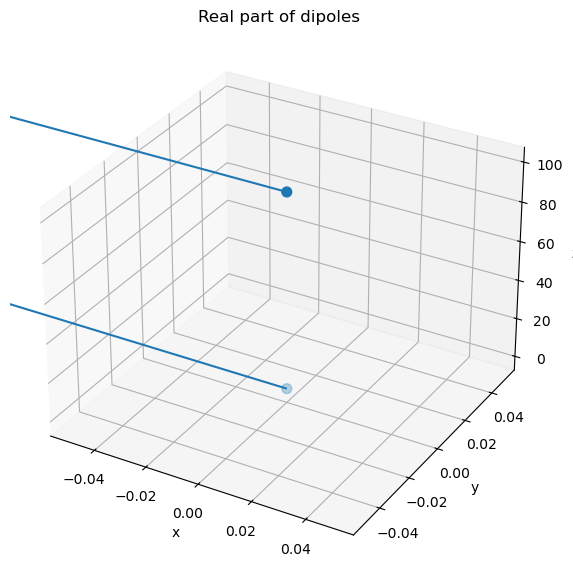

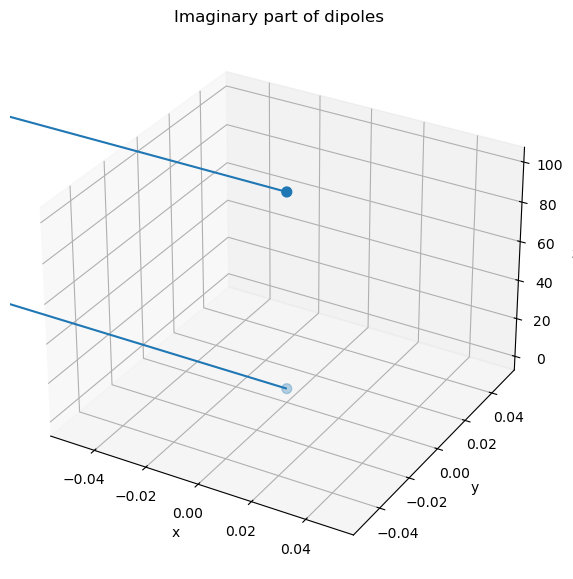

In [55]:
import numpy as np
import matplotlib.pyplot as plt

iw = 36
layer_separation = 100.0  # nm


positions = np.array([[0,0,0],[0,0,layer_separation]])
dips = dips_simple_list[0][iw]   # (10, 3)
pos = positions        # (10, 3)

# ---------- real part ----------
d_real = np.real(dips)
scale_real = 100 / np.max(np.linalg.norm(d_real, axis=1))
d_real_plot = d_real * scale_real

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_real_plot[:, 0],
    d_real_plot[:, 1],
    d_real_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Real part of dipoles')

plt.show()


# ---------- imaginary part ----------
d_imag = np.imag(dips)
scale_imag = 100 / np.max(np.linalg.norm(d_imag, axis=1))
d_imag_plot = d_imag * scale_imag

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_imag_plot[:, 0],
    d_imag_plot[:, 1],
    d_imag_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Imaginary part of dipoles')

plt.show()

In [66]:
import numpy as np
import matplotlib.pyplot as plt

iw = 54
layer_separation = 100.0  # nm

bottom_xyz = np.column_stack([
    bottom_xy,
    np.zeros(len(bottom_xy))
])

top_xyz = np.column_stack([
    top_xy,
    np.full(len(top_xy), layer_separation)
])

positions = np.vstack([
    bottom_xyz,
    top_xyz
])
dips = dips_list[0][iw]   # (10, 3)
pos = positions        # (10, 3)

# ---------- real part ----------
d_real = np.real(dips)
scale_real = 100 / np.max(np.linalg.norm(d_real, axis=1))
d_real_plot = d_real * scale_real

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_real_plot[:, 0],
    d_real_plot[:, 1],
    d_real_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Real part of dipoles')

plt.savefig(f"../../figures/dipoles_twist_second_resonance_real")
plt.close()
# ---------- imaginary part ----------
d_imag = np.imag(dips)
scale_imag = 100 / np.max(np.linalg.norm(d_imag, axis=1))
d_imag_plot = d_imag * scale_imag

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_imag_plot[:, 0],
    d_imag_plot[:, 1],
    d_imag_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Imaginary part of dipoles')

plt.savefig(f"../../figures/dipoles_twist_second_resonance_imag")
plt.close()

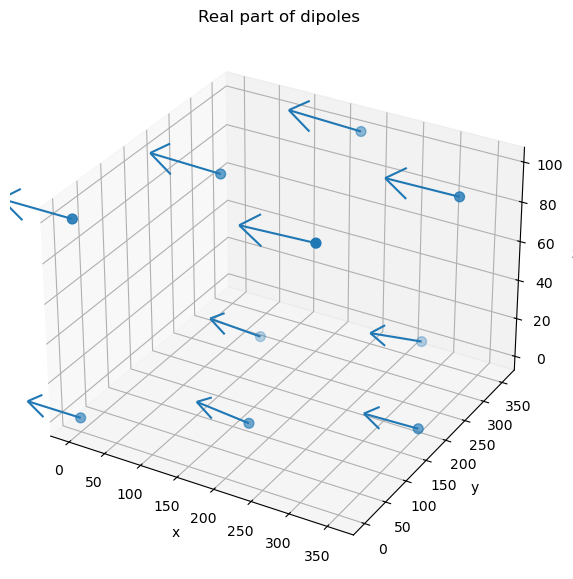

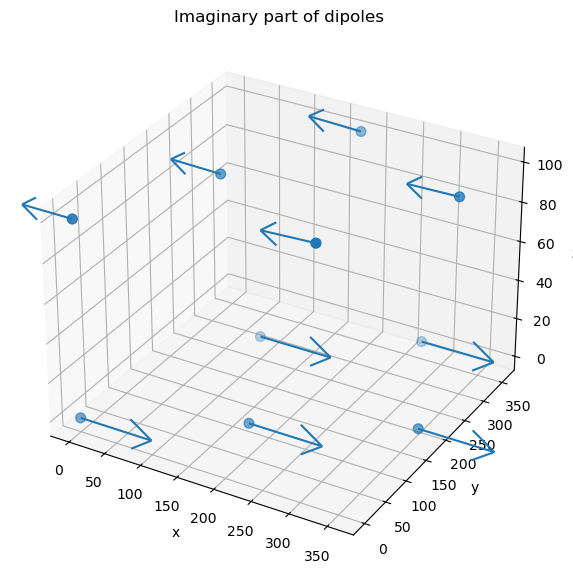

In [69]:
import numpy as np
import matplotlib.pyplot as plt

iw = 5
layer_separation = 100.0  # nm

bottom_xyz = np.column_stack([
    bottom_xy,
    np.zeros(len(bottom_xy))
])

top_xyz = np.column_stack([
    top_xy,
    np.full(len(top_xy), layer_separation)
])

positions = np.vstack([
    bottom_xyz,
    top_xyz
])
dips = dips_list[0][iw]   # (10, 3)
pos = positions        # (10, 3)

# ---------- real part ----------
d_real = np.real(dips)
scale_real = 100 / np.max(np.linalg.norm(d_real, axis=1))
d_real_plot = d_real * scale_real

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_real_plot[:, 0],
    d_real_plot[:, 1],
    d_real_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Real part of dipoles')
plt.show()
# plt.savefig(f"../../figures/dipoles_twist_second_resonance_real")
# plt.close()
# ---------- imaginary part ----------
d_imag = np.imag(dips)
scale_imag = 100 / np.max(np.linalg.norm(d_imag, axis=1))
d_imag_plot = d_imag * scale_imag

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=50)

ax.quiver(
    pos[:, 0], pos[:, 1], pos[:, 2],
    d_imag_plot[:, 0],
    d_imag_plot[:, 1],
    d_imag_plot[:, 2]
)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Imaginary part of dipoles')
plt.show()
# plt.savefig(f"../../figures/dipoles_twist__imag")
# plt.close()